### Delving into non-parametric methods using pandas and scipy
* **Purpose:** Measure correlation and test independence when data does **not** meet Pearson's assumptions (such as **categorical**, **ordinal**, **nonlinear**, or **non-normally distributed** variables).
* **Libraries Used:**
  * **`pandas`:** Used to organize data and build frequency/contingency tables (`pd.crosstab()`).
  * **`scipy.stats`:** Used to run statistical tests — **`spearmanr()`** for ordinal variables and **`chi2_contingency()`** for categorical variables.

  ## Spearman rank correlation and Chi-square

### 1. Nonparametric Correlation Analysis
* Used to find correlation between **categorical**, **nonlinearly related**, or **non-normally distributed** variables (where Pearson correlation cannot be used).
* Two main nonparametric methods:
  1. **Spearman’s rank correlation**
  2. **Chi-square tables**

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from pylab import rcParams

import scipy
from scipy.stats import spearmanr

In [2]:
%matplotlib inline
rcParams['figure.figsize'] = 14, 7
sns.set_style("whitegrid")

In [ ]:
# Load the mtcars dataset from the CSV file
cars = pd.read_csv('../../data/mtcars.csv')
cars.columns = ['car_names','mpg','cyl','disp', 'hp', 'drat', 'wt', 'qsec', 'vs', 'am', 'gear', 'carb']
cars.head()

,car_names,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


### 1. Spearman’s Rank Correlation
* Finds the $R$ correlation between **ordinal variables** by ranking variable pairs according to the strength of their relationship.
* **Ordinal Variable:** A variable with categories that have a natural order or ranking (e.g., *Small < Medium < Large*, or *3 gears < 4 gears < 5 gears*).
* **Spearman’s Rank Correlation Coefficient ($R$):**
  * **$R = 1$:** Strong positive relationship
  * **$R = 0$:** Not correlated
  * **$R = -1$:** Strong negative relationship
* **Spearman’s Correlation Assumptions:**
  1. Your variables are **ordinal** (numeric or categorical values that can be ranked).
  2. Your variables are related **nonlinearly**.
  3. Your data is **non-normally distributed**.

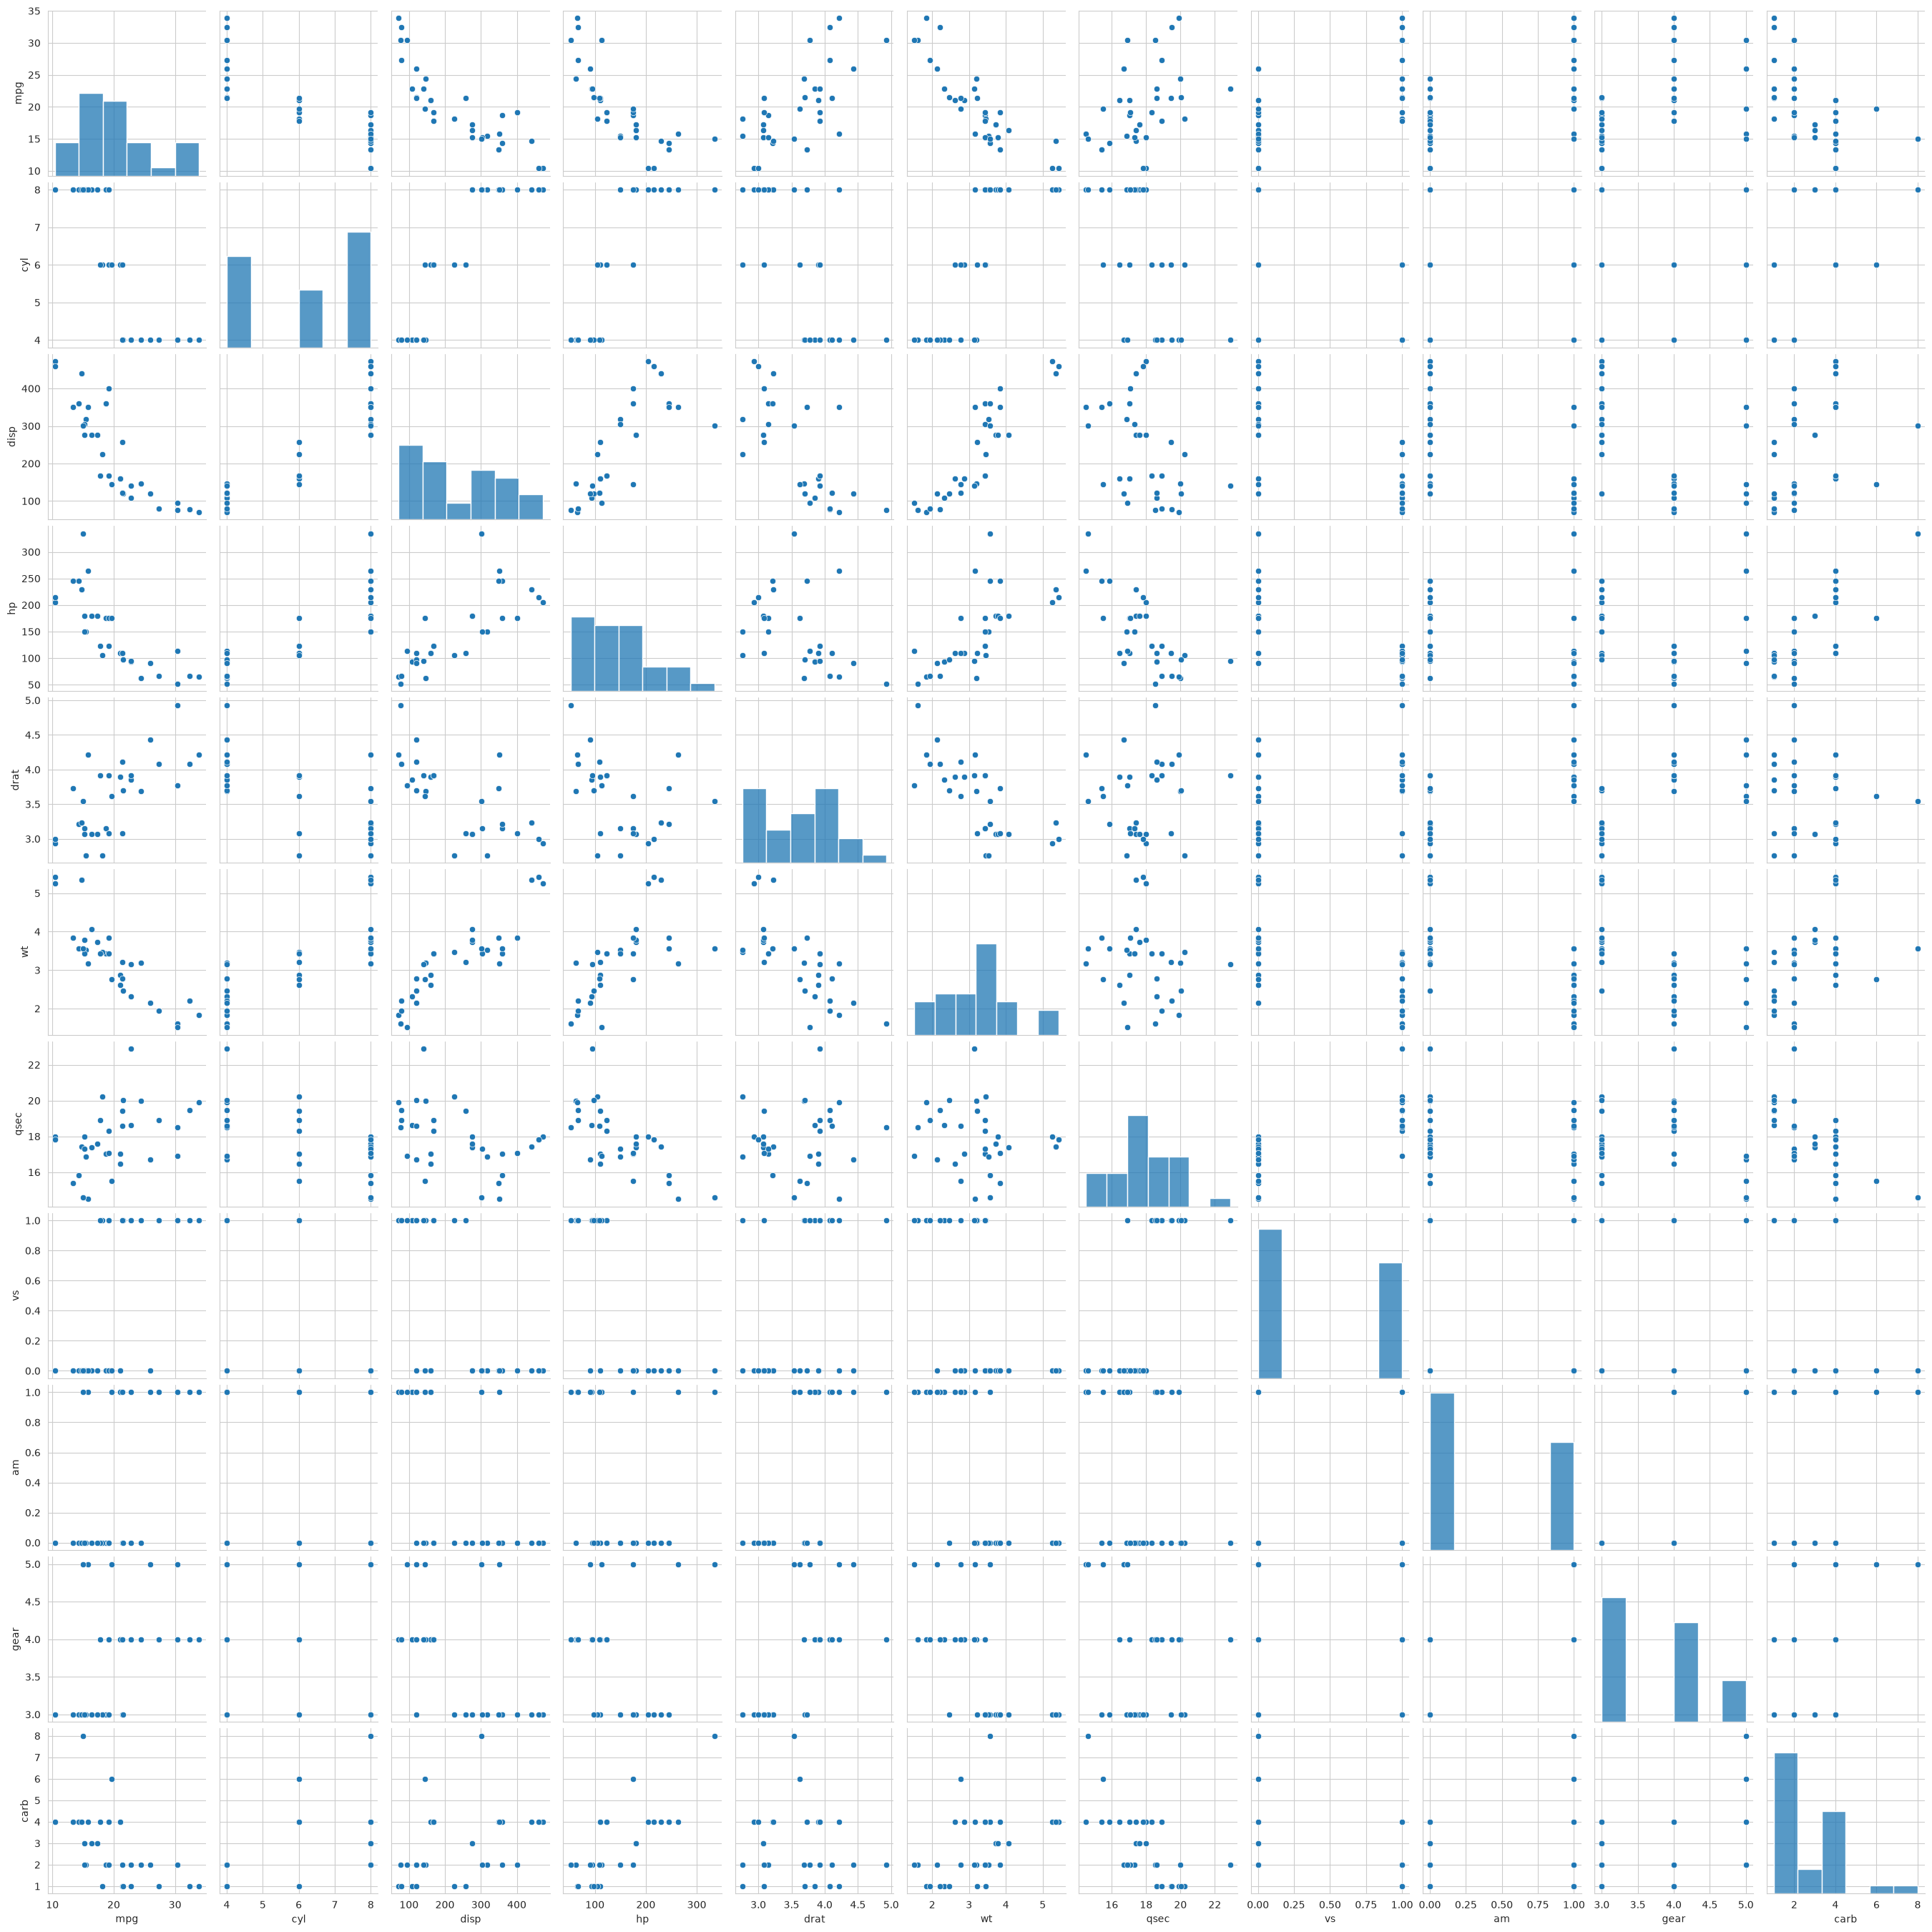

In [4]:
sns.pairplot(cars)

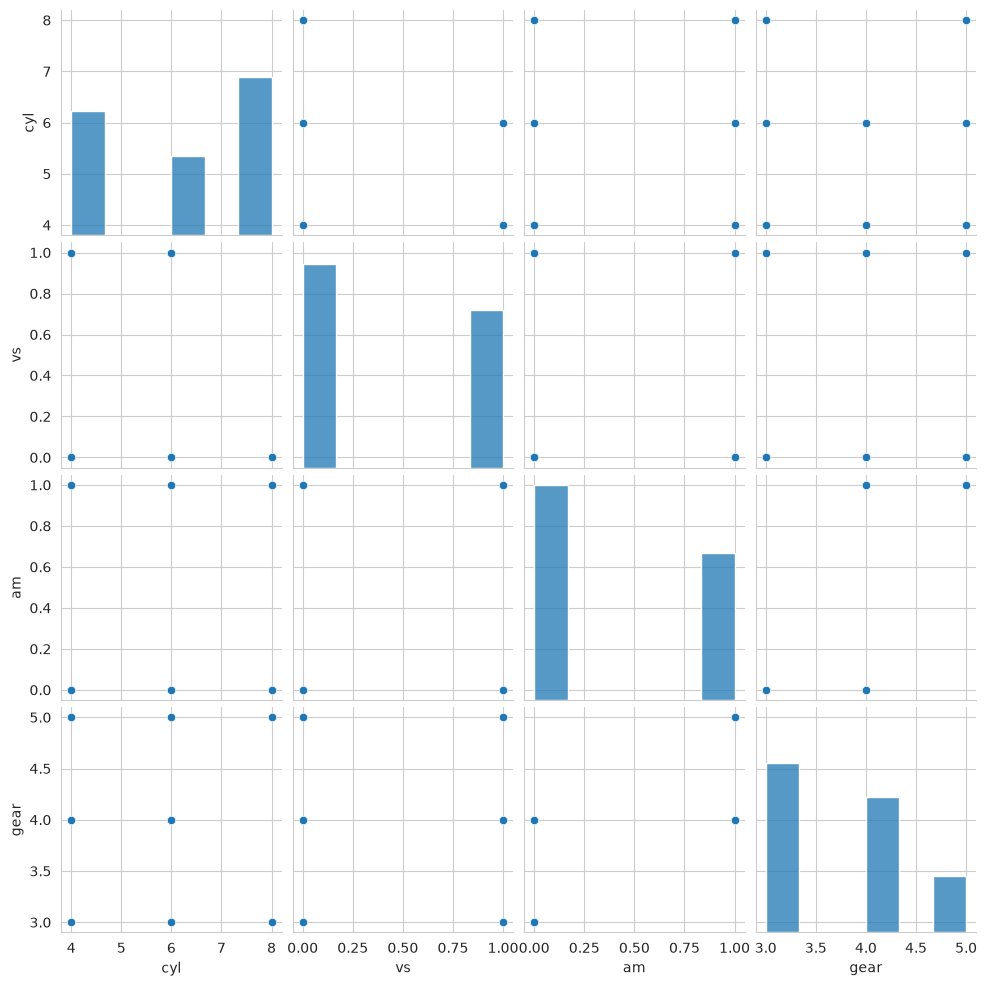

In [ ]:
# Create the subset 4 ordinal/categorical columns ('cyl', 'vs', 'am', 'gear') from 'cars' and store in 'x'
x = cars[['cyl', 'vs', 'am', 'gear']]

# Create a pairplot to confirm these variables are categorical/ordinal (discrete dots and bars instead of continuous lines)
sns.pairplot(x)

In [6]:
# Import spearmanr function from scipy.stats to calculate Spearman rank correlation
from scipy.stats import spearmanr

# Extract the 4 ordinal/categorical columns into separate variables
cyl = cars['cyl']
vs = cars['vs']
am = cars['am']
gear = cars['gear']

# Calculate Spearman rank correlation coefficient (R) and p-value between 'cyl' and 'vs'
spearmanr_coefficient, p_value = spearmanr(cyl, vs)

# Print correlation rounded to 3 decimal places using f-string (Output: -0.814, strong negative relationship)
print(f'Spearman Rank Correlation Coefficient {spearmanr_coefficient:.3f}')

Spearman Rank Correlation Coefficient -0.814


In [8]:
# Calculate Spearman rank correlation coefficient (R) and p-value between 'cyl' and 'vs'
spearmanr_coefficient, p_value = spearmanr(cyl, gear)

# Print correlation rounded to 3 decimal places using f-string (Output: -0.814, strong negative relationship)
print(f'Spearman Rank Correlation Coefficient {spearmanr_coefficient:.3f}')

Spearman Rank Correlation Coefficient -0.564


### 2. Chi-Square Tables Test for Independence
* **Hypothesis (Null Hypothesis):** The starting assumption that two variables have **no relationship** (they are independent).
* **Decision Rule using $p$-value:**
  * **$p < 0.05$:** **Reject** the null hypothesis $\rightarrow$ the variables are **correlated**.
  * **$p > 0.05$:** **Accept** the null hypothesis $\rightarrow$ the variables are **independent** (not correlated).
* **When to Use Chi-Square Tables:**
  * Your variables are **categorical** or **numeric**.
  * You have **binned** the numeric variables into intervals (e.g., `0–20`, `20–40`, `40–60`).

* **Role of Pandas (`pd`):** `pd.crosstab(cyl, am)` creates a contingency (frequency) table counting the combinations of two categorical variables.
* **Role of SciPy (`chi2_contingency`):** Runs the Chi-square test on `table.values` and returns 4 results: `chi2` (statistic), `p` (p-value), `dof` (degrees of freedom), and `expected` (expected table).
* **Result Interpretation:**
  * **Chi-square Statistic:** `8.741`
  * **$p$-value:** `0.013`
  * Since **$p < 0.05$**, we **reject the null hypothesis** and conclude that `cyl` and `am` are **correlated** (not independent).

In [9]:
# Create a frequency table (crosstab) of 'cyl' and 'am' using pandas
table = pd.crosstab(cyl, am)

# Import chi2_contingency function from scipy.stats for the Chi-square test
from scipy.stats import chi2_contingency

# Run the Chi-square test on the table values (returns chi2 statistic, p-value, degrees of freedom, and expected frequencies)
chi2, p, dof, expected = chi2_contingency(table.values)

# Print Chi-square statistic and p-value rounded to 3 decimal places
# Output meaning: p_value = 0.013 (< 0.05), so we reject the null hypothesis — 'cyl' and 'am' are correlated
print(f'Chi-square Statistic {chi2:.3f} p_value {p:.3f}')

Chi-square Statistic 8.741 p_value 0.013


### Additional Chi-Square Tests (`cyl` vs. `vs` and `cyl` vs. `gear`)

* **`cyl` vs. `vs`:** `Chi-square Statistic = 21.340`, **`p_value = 0.000`** ($< 0.05$) $\rightarrow$ Reject null hypothesis; **`cyl` and `vs` are correlated**.
* **`cyl` vs. `gear`:** `Chi-square Statistic = 18.036`, **`p_value = 0.001`** ($< 0.05$) $\rightarrow$ Reject null hypothesis; **`cyl` and `gear` are correlated**.


In [10]:
# Create a crosstab frequency table for 'cyl' and 'vs'
table = pd.crosstab(cyl, vs)

# Run Chi-square test of independence on the table values
chi2, p, dof, expected = chi2_contingency(table.values)

# Print Chi-square statistic and p-value rounded to 3 decimal places
# Output meaning: p_value = 0.000 (< 0.05), so 'cyl' and 'vs' are strongly correlated
print(f'Chi-square Statistic {chi2:.3f} p_value {p:.3f}')

Chi-square Statistic 21.340 p_value 0.000


In [11]:
# Create a crosstab frequency table for 'cyl' and 'gear'
table = pd.crosstab(cyl, gear)

# Run Chi-square test of independence on the table values
chi2, p, dof, expected = chi2_contingency(table.values)

# Print Chi-square statistic and p-value rounded to 3 decimal places
# Output meaning: p_value = 0.001 (< 0.05), so 'cyl' and 'gear' are also correlated
print(f'Chi-square Statistic {chi2:.3f} p_value {p:.3f}')

Chi-square Statistic 18.036 p_value 0.001
